# AI5707 Assignment 6 — GMM, Custom K-Means, and Distortion Classification

This notebook follows the assignment requirements: two classes, three Gaussian components per class, covariance experiments (spherical, diagonal, full), an 80:20 split, K-Means implemented from scratch, and test classification by distortion.



## Cell 1 — Imports

In [13]:
import random
import math
import numpy as np
import matplotlib.pyplot as plt

random.seed(42)
plt.rcParams["figure.figsize"] = (8, 5)
print("Imports completed.")

Imports completed.


## Cell 2 — Box–Muller method

For independent uniform random variables \(U_1,U_2 \in (0,1)\), the Box–Muller transformation gives

$$ [
Z_0 = \sqrt{-2\ln U_1}\cos(2\pi U_2)
 ]
$$

$$
[
 Z_1 = \sqrt{-2\ln U_1}\sin(2\pi U_2)
]
$$

The resulting values are independent standard normal samples. Each iteration produces two values.

In [14]:
def box_muller(n):
    values = []
    while len(values) < n:
        u1 = random.random()
        u2 = random.random()
        while u1 == 0.0:
            u1 = random.random()
        radius = math.sqrt(-2.0 * math.log(u1))
        angle = 2.0 * math.pi * u2
        values.extend([
            radius * math.cos(angle),
            radius * math.sin(angle)
        ])
    return np.array(values[:n], dtype=float)



## Cell 3 — Generate 2D Gaussian Samples 

For the covariance matrix

$$
C =
\begin{bmatrix}
a & b \\
b & d
\end{bmatrix}
$$

independent standard normal random variables $Z_1$ and $Z_2$ are transformed to generate samples with the required mean and covariance.

### Variables and Their Meaning

- **$C$**: The target $2 \times 2$ covariance matrix.
- **$a$**: Variance of the first feature $X_1$.
- **$b$**: Covariance between the two features $X_1$ and $X_2$.
- **$d$**: Variance of the second feature $X_2$.
- **$\mu_1$**: Desired mean of the first feature.
- **$\mu_2$**: Desired mean of the second feature.
- **$Z_1$**: First independent standard normal random variable, with mean $0$ and variance $1$.
- **$Z_2$**: Second independent standard normal random variable, with mean $0$ and variance $1$.
- **$X_1$**: Generated first feature with mean $\mu_1$ and variance $a$.
- **$X_2$**: Generated second feature with mean $\mu_2$ and variance $d$.
- **$n$**: Number of random samples to generate.
- **$\sqrt{a}$**: Scaling factor that gives $X_1$ the required variance.
- **$\frac{b}{\sqrt{a}}$**: Coefficient that introduces the required covariance between the features.
- **$\sqrt{d-\frac{b^2}{a}}$**: Scaling factor for the independent noise in $X_2$, ensuring the correct remaining variance.

### Transformation Equations

The first feature is generated as

$$
X_1 = \mu_1 + \sqrt{a}\,Z_1
$$

The second feature is generated as

$$
X_2 =
\mu_2 + \frac{b}{\sqrt{a}}Z_1
+ \sqrt{d-\frac{b^2}{a}}\,Z_2
$$

### Conditions

For the transformation to generate a valid, non-degenerate Gaussian distribution, the covariance matrix must be positive definite:

$$
a > 0
$$

$$
d-\frac{b^2}{a} > 0
$$

The covariance matrix must also be symmetric.

### Sample Generation Process

1. Generate $n$ independent values each for $Z_1$ and $Z_2$ from the standard normal distribution.
2. Scale and shift $Z_1$ to obtain $X_1$.
3. Combine $Z_1$ and $Z_2$ to obtain $X_2$, introducing the required covariance.
4. Combine $X_1$ and $X_2$ into an $n \times 2$ data matrix.
5. The generated samples approximate the specified mean vector and full covariance matrix.

This method generates correlated two-dimensional Gaussian samples **without using Cholesky decomposition**.


In [15]:
def generate_2d_gaussian(n, mean, covariance):
    mu1, mu2 = mean
    a = float(covariance[0, 0])
    b = float(covariance[0, 1])
    b2 = float(covariance[1, 0])
    d = float(covariance[1, 1])

    if not math.isclose(b, b2, rel_tol=1e-9, abs_tol=1e-9):
        raise ValueError("Covariance matrix must be symmetric.")
    if a <= 0 or d - b*b/a <= 0:
        raise ValueError("Covariance matrix must be positive definite.")

    z1 = box_muller(n)
    z2 = box_muller(n)
    x1 = mu1 + math.sqrt(a) * z1
    x2 = mu2 + (b / math.sqrt(a)) * z1 + math.sqrt(d - b*b/a) * z2
    return np.column_stack((x1, x2))


## Cell 4 — Gaussian mixture generator

A Gaussian mixture model has density

$$
 
    
p(\mathbf{x}) = \sum_{i=1}^{K} \pi_i
\mathcal{N}(\mathbf{x};\boldsymbol{\mu}_i,C_i),
\qquad \sum_{i=1}^{K}\pi_i=1
 
 
 $$

Sample counts are allocated according to the mixture weights. Samples from each Gaussian component are then combined and shuffled.

In [16]:
def allocate_counts(n_samples, weights):
    weights = np.asarray(weights, dtype=float)
    if np.any(weights < 0) or weights.sum() <= 0:
        raise ValueError("Weights must be non-negative with positive sum.")
    weights = weights / weights.sum()
    raw = n_samples * weights
    counts = np.floor(raw).astype(int)
    remaining = n_samples - counts.sum()
    order = np.argsort(-(raw - counts))
    for j in range(remaining):
        counts[order[j]] += 1
    return counts


def generate_gmm(n_samples, weights, means, covariances):
    if not (len(weights) == len(means) == len(covariances)):
        raise ValueError("Weights, means, and covariances must have equal lengths.")
    counts = allocate_counts(n_samples, weights)
    sample_parts = []
    component_ids = []
    for i, count in enumerate(counts):
        Xi = generate_2d_gaussian(int(count), means[i], covariances[i])
        sample_parts.append(Xi)
        component_ids.extend([i] * int(count))
    X_mix = np.vstack(sample_parts)
    component_ids = np.array(component_ids, dtype=int)
    indices = list(range(n_samples))
    random.shuffle(indices)
    return X_mix[indices], component_ids[indices]


print("Gaussian mixture generator ready.")

Gaussian mixture generator ready.


## Cell 5 — Define classes and covariance types

Each class has three Gaussian components. Parameters are empirically selected for visualization and classification.

In [17]:
weights = [0.40, 0.20, 0.40]
N_PER_CLASS = 1500

means_class0 = [[-3.0, 2.0], [-3.0, 0.0], [-3.0, -2.0]]
means_class1 = [[ 3.0, 2.0], [ 3.0, 0.0], [ 3.0, -2.0]]

covariance_types = {
    "Spherical": [
        0.65**2 * np.eye(2),
        0.55**2 * np.eye(2),
        0.65**2 * np.eye(2)
    ],
    "Diagonal": [
        np.array([[1.00, 0.00], [0.00, 0.40]]),
        np.array([[0.45, 0.00], [0.00, 0.80]]),
        np.array([[1.00, 0.00], [0.00, 0.40]])
    ],
    "Full": [
        np.array([[0.80, 0.30], [0.30, 0.50]]),
        np.array([[0.65, -0.20], [-0.20, 0.70]]),
        np.array([[0.80, 0.30], [0.30, 0.50]])
    ]
}

def generate_two_classes(cov_type):
    covs = covariance_types[cov_type]
    X0, comp0 = generate_gmm(N_PER_CLASS, weights, means_class0, covs)
    X1, comp1 = generate_gmm(N_PER_CLASS, weights, means_class1, covs)
    return X0, comp0, X1, comp1

print("Components per class:", len(means_class0))
print("Mixture weights:", weights, "sum =", sum(weights))

Components per class: 3
Mixture weights: [0.4, 0.2, 0.4] sum = 1.0


## Cell 6 — Plot all covariance experiments

Each row shows a covariance type. Each column shows one class. Point colours identify the Gaussian component.

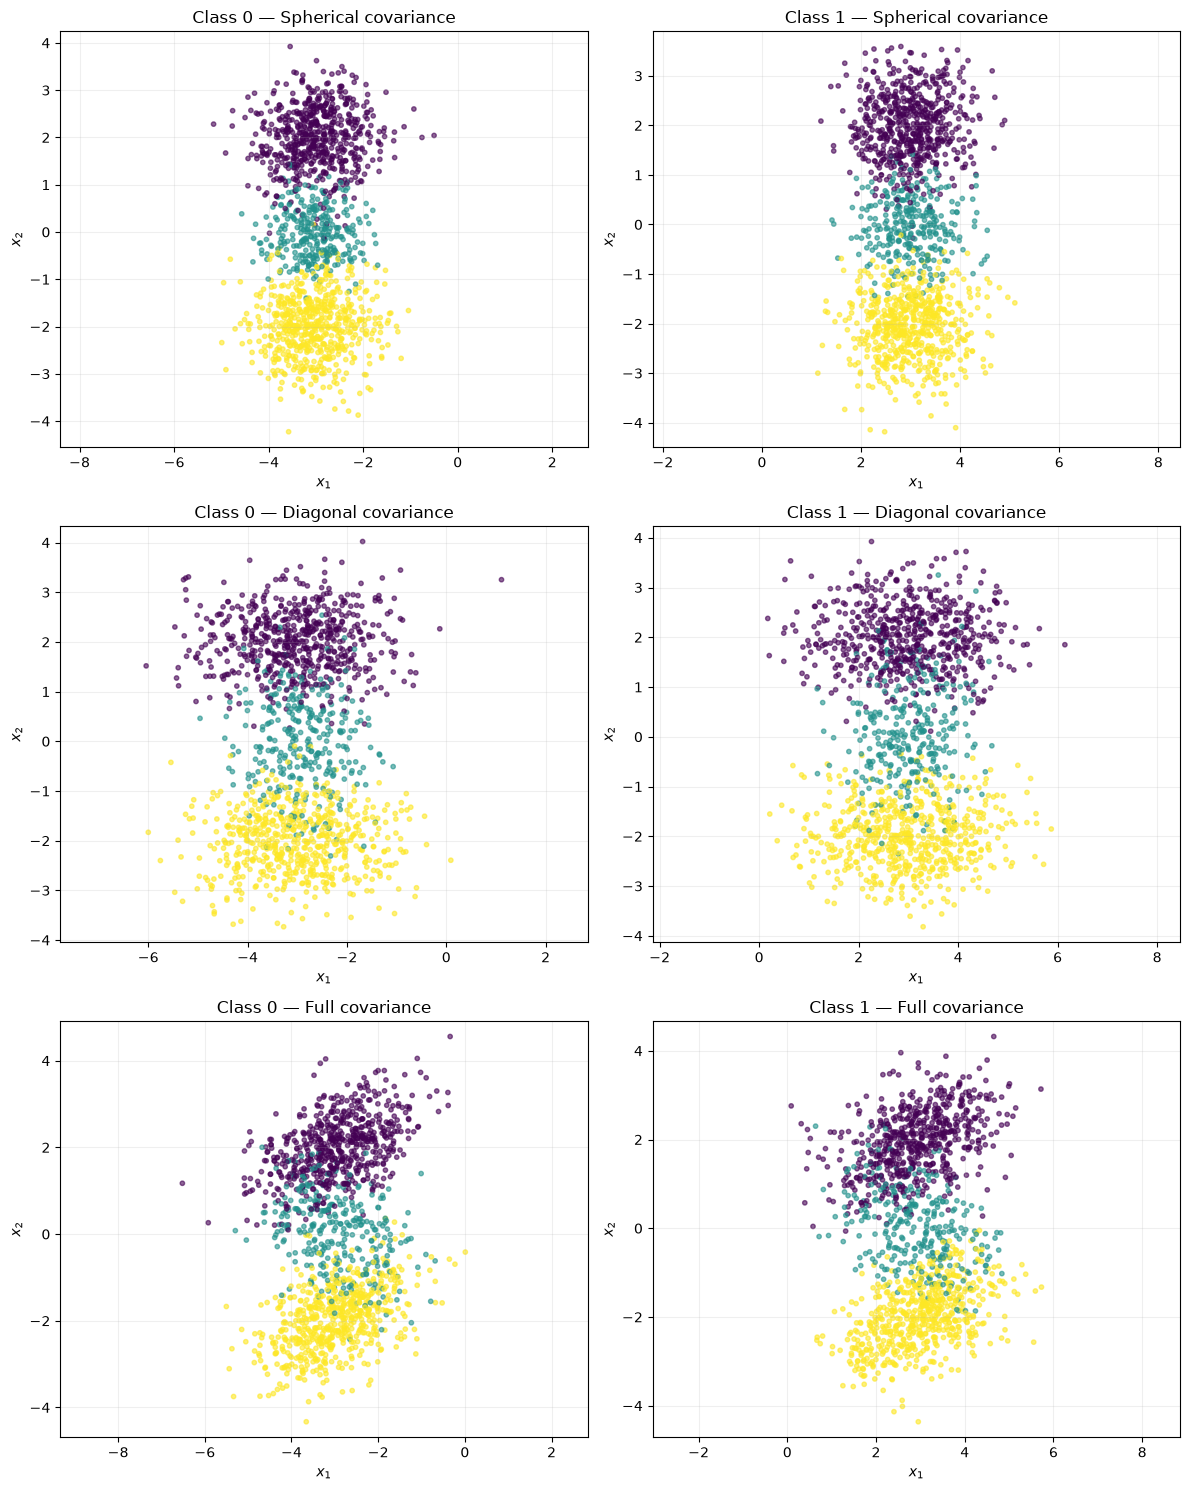

In [18]:
random.seed(42)
fig, axes = plt.subplots(3, 2, figsize=(12, 15))

for row, cov_type in enumerate(["Spherical", "Diagonal", "Full"]):
# for row, cov_type in enumerate(["Full"]):    
    X0, comp0, X1, comp1 = generate_two_classes(cov_type)
    for ax, Xi, compi, cls in [
        (axes[row, 0], X0, comp0, 0),
        (axes[row, 1], X1, comp1, 1)
    ]:
        ax.scatter(Xi[:, 0], Xi[:, 1], c=compi, cmap="viridis", s=10, alpha=0.60)
        ax.set_title(f"Class {cls} — {cov_type} covariance")
        ax.set_xlabel("$x_1$")
        ax.set_ylabel("$x_2$")
        ax.axis("equal")
        ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## Cell 7 — Generate final data and split 80:20

The full-covariance data are used for the main classification experiment. The classes are split separately so each has an 80% training set and a 20% test set.

In [19]:
random.seed(2026)
covs = covariance_types["Full"]
X_class0, comp_class0 = generate_gmm(N_PER_CLASS, weights, means_class0, covs)
X_class1, comp_class1 = generate_gmm(N_PER_CLASS, weights, means_class1, covs)

def split_80_20(X, train_fraction=0.8):
    indices = list(range(len(X)))
    random.shuffle(indices)
    split_at = int(train_fraction * len(X))
    return X[indices[:split_at]], X[indices[split_at:]]

X0_train, X0_test = split_80_20(X_class0)
X1_train, X1_test = split_80_20(X_class1)

X_train = np.vstack((X0_train, X1_train))
y_train = np.concatenate((np.zeros(len(X0_train), dtype=int),
                          np.ones(len(X1_train), dtype=int)))
X_test = np.vstack((X0_test, X1_test))
y_test = np.concatenate((np.zeros(len(X0_test), dtype=int),
                         np.ones(len(X1_test), dtype=int)))

print("Class 0 train/test:", len(X0_train), "/", len(X0_test))
print("Class 1 train/test:", len(X1_train), "/", len(X1_test))
print("Combined train/test:", len(X_train), "/", len(X_test))

Class 0 train/test: 1200 / 300
Class 1 train/test: 1200 / 300
Combined train/test: 2400 / 600


## Cell 8 — K-Means from scratch

K-Means repeatedly assigns points to their nearest centroid and updates each centroid to the mean of its assigned points. No `sklearn` is used.

In [20]:
def kmeans(X, K, max_iters=100, tol=1e-4):
    if K < 1 or K > len(X):
        raise ValueError("K must be between 1 and the number of samples.")

    indices = list(range(len(X)))
    random.shuffle(indices)
    centroids = X[indices[:K]].copy()

    for iteration in range(max_iters):
        distances = np.sum(
            (X[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2,
            axis=2
        )
        labels = np.argmin(distances, axis=1)
        new_centroids = centroids.copy()

        for k in range(K):
            cluster_points = X[labels == k]
            if len(cluster_points) > 0:
                new_centroids[k] = np.mean(cluster_points, axis=0)

        shift = math.sqrt(float(np.sum((new_centroids - centroids) ** 2)))
        centroids = new_centroids
        if shift < tol:
            break

    distances = np.sum(
        (X[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2,
        axis=2
    )
    labels = np.argmin(distances, axis=1)
    return centroids, labels, iteration + 1


K = 2
random.seed(42)
centroids0, labels0, iters0 = kmeans(X0_train, K)
centroids1, labels1, iters1 = kmeans(X1_train, K)

print("Class 0 centroids:\n", centroids0)
print("Class 0 iterations:", iters0)
print("\nClass 1 centroids:\n", centroids1)
print("Class 1 iterations:", iters1)

Class 0 centroids:
 [[-2.95064761 -1.75267575]
 [-3.09714631  1.68743981]]
Class 0 iterations: 6

Class 1 centroids:
 [[ 2.94470886  1.59652119]
 [ 3.05917185 -1.80426555]]
Class 1 iterations: 7


## Cell 9 — Plot K-Means regions and centroids

These are the within-class nearest-centroid regions, not the final class-vs-class boundary.

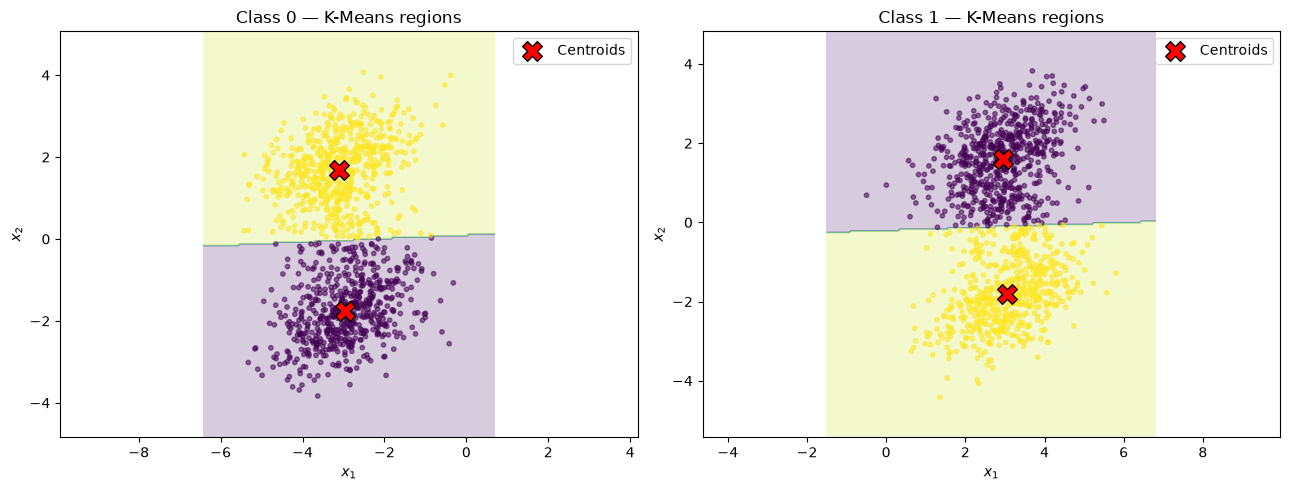

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, Xtr, centroids, labels, title in [
    (axes[0], X0_train, centroids0, labels0, "Class 0"),
    (axes[1], X1_train, centroids1, labels1, "Class 1")
]:
    x_min, x_max = Xtr[:, 0].min() - 1, Xtr[:, 0].max() + 1
    y_min, y_max = Xtr[:, 1].min() - 1, Xtr[:, 1].max() + 1
    
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250),
                         np.linspace(y_min, y_max, 250))
    
    grid = np.column_stack((xx.ravel(), yy.ravel()))
    grid_distances = np.sum(
        (grid[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2,
        axis=2
    )
    regions = np.argmin(grid_distances, axis=1).reshape(xx.shape)

    ax.contourf(xx, yy, regions, alpha=0.22, cmap="viridis")
    ax.scatter(Xtr[:, 0], Xtr[:, 1], c=labels, cmap="viridis", s=10, alpha=0.55)
    ax.scatter(centroids[:, 0], centroids[:, 1], marker="X", s=200,
               c="red", edgecolors="black", label="Centroids")
    ax.set_title(title + " — K-Means regions")
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.legend()
    ax.axis("equal")

plt.tight_layout()
plt.show()


## Cell 10 — Distortion-Based Classification

For a test point $\mathbf{x}$, the distortion to class $c$ is the
minimum squared distance to its centroids:

$$
D_c(\mathbf{x}) = \min_k \left\| \mathbf{x} - \boldsymbol{\mu}_{c,k} \right\|^2
$$

The predicted class is the one with the smaller distortion.


In [22]:
def distortion_to_centroids(X, centroids):
    distances = np.sum(
        (X[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2,
        axis=2
    )
    return np.min(distances, axis=1)


d0 = distortion_to_centroids(X_test, centroids0)
d1 = distortion_to_centroids(X_test, centroids1)
y_pred = (d1 < d0).astype(int)
accuracy = np.mean(y_pred == y_test)

cm = np.zeros((2, 2), dtype=int)
for actual, predicted in zip(y_test, y_pred):
    cm[actual, predicted] += 1

print(f"Test accuracy: {accuracy:.4f} ({accuracy:.2%})")
print("Confusion matrix (rows=true class, columns=predicted class):")
print(cm)
print("Correct predictions:", int(np.sum(y_pred == y_test)))
print("Incorrect predictions:", int(np.sum(y_pred != y_test)))

Test accuracy: 1.0000 (100.00%)
Confusion matrix (rows=true class, columns=predicted class):
[[300   0]
 [  0 300]]
Correct predictions: 600
Incorrect predictions: 0


## Cell 11 — Plot test predictions

Correct predictions are filled points; errors are shown with black outlines.

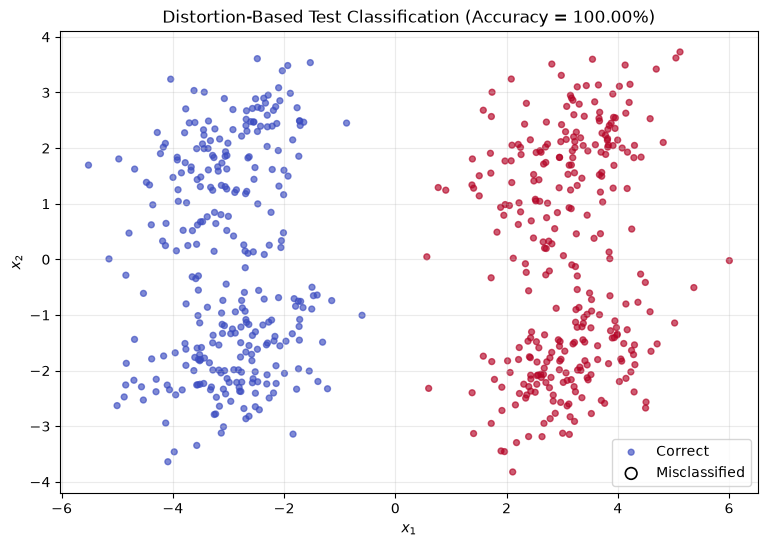

In [23]:
correct = y_pred == y_test
plt.figure(figsize=(9, 6))
plt.scatter(X_test[correct, 0], X_test[correct, 1],
            c=y_pred[correct], cmap="coolwarm", s=18, alpha=0.65,
            label="Correct")
plt.scatter(X_test[~correct, 0], X_test[~correct, 1],
            facecolors="none", edgecolors="black", s=70,
            linewidths=1.2, label="Misclassified")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title(f"Distortion-Based Test Classification (Accuracy = {accuracy:.2%})")
plt.legend()
plt.grid(alpha=0.25)
plt.axis("equal")
plt.show()

## Cell 12 — Compare covariance types

This optional experiment evaluates the custom K-Means distortion classifier for each covariance type.

Spherical : 100.00%
Diagonal  : 99.83%
Full      : 100.00%


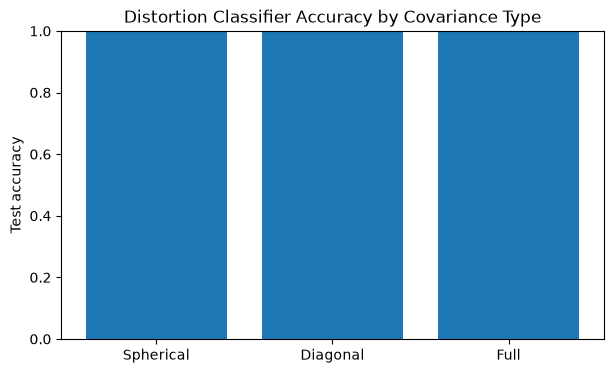

In [24]:
def evaluate_covariance_type(cov_type):
    covs = covariance_types[cov_type]
    X0, _ = generate_gmm(N_PER_CLASS, weights, means_class0, covs)
    X1, _ = generate_gmm(N_PER_CLASS, weights, means_class1, covs)
    X0tr, X0te = split_80_20(X0)
    X1tr, X1te = split_80_20(X1)

    c0, _, _ = kmeans(X0tr, K)
    c1, _, _ = kmeans(X1tr, K)

    Xte = np.vstack((X0te, X1te))
    yte = np.concatenate((np.zeros(len(X0te), dtype=int),
                          np.ones(len(X1te), dtype=int)))
    dist0 = distortion_to_centroids(Xte, c0)
    dist1 = distortion_to_centroids(Xte, c1)
    pred = (dist1 < dist0).astype(int)
    return float(np.mean(pred == yte))


random.seed(123)
comparison = {}
for cov_type in ["Spherical", "Diagonal", "Full"]:
    comparison[cov_type] = evaluate_covariance_type(cov_type)

for cov_type, score in comparison.items():
    print(f"{cov_type:10s}: {score:.2%}")

plt.figure(figsize=(7, 4))
plt.bar(list(comparison.keys()), list(comparison.values()))
plt.ylim(0, 1)
plt.ylabel("Test accuracy")
plt.title("Distortion Classifier Accuracy by Covariance Type")
plt.show()

## Observations and conclusion

Fill in the actual accuracy and confusion matrix after running the notebook.

1. Box–Muller transforms uniform random values into standard normal samples.
2. The manual covariance transformation generates 2D Gaussian samples with the selected mean and covariance.
3. Spherical covariance creates approximately circular components; diagonal covariance creates axis-aligned ellipses; full covariance allows correlated and tilted ellipses.
4. K-Means assigns each training point to its nearest centroid and updates centroids using cluster means.
5. The distortion classifier predicts the class whose nearest centroid has the smaller squared distance.
6. Performance depends on class separation, covariance structure, and how well centroids represent the distributions.

Accuracy depends on the chosen parameters and generated samples. Report the measured results from your run.